# 8.5 EDPs Hiperbólicas

Equações hiperbólicas descrevem fenômenos de **propagação de ondas**: as vibrações de uma corda ou de uma membrana, o som em um tubo, as ondas de pressão em uma tubulação. O modelo básico é a **equação da onda** unidimensional

$$\frac{\partial^2 u}{\partial t^2}=c^2\,\frac{\partial^2 u}{\partial x^2},\qquad 0<x<L,\quad t>0, \tag{1}$$

em que $u(x,t)$ é o deslocamento transversal de uma corda de comprimento $L$ no ponto $x$ e no instante $t$, e $c>0$ é a velocidade de propagação das ondas, determinada pela tensão e pela densidade da corda. Na forma geral da Seção 8.2, com $t$ no papel de $y$, temos $A=c^2$, $B=0$ e $C=-1$, de modo que $B^2-4AC=4c^2>0$: é o caso hiperbólico.

Como a equação tem derivada segunda no tempo, precisamos de **duas condições iniciais**, a posição e a velocidade de cada ponto da corda, além de uma condição em cada extremidade:

$$u(x,0)=f(x),\qquad \frac{\partial u}{\partial t}(x,0)=g(x),\qquad u(0,t)=a(t),\qquad u(L,t)=b(t). \tag{2}$$

Uma diferença essencial em relação à equação do calor aparece na solução de d'Alembert: em um meio ilimitado, toda solução da Eq. (1) tem a forma $u(x,t)=F(x-ct)+G(x+ct)$, isto é, é a soma de duas ondas que viajam sem se deformar, uma para a direita e outra para a esquerda, com velocidade $c$. As perturbações não são amortecidas, como na difusão, e se propagam com **velocidade finita**: o valor de $u$ em $(x,t)$ depende apenas dos dados iniciais no intervalo $[x-ct,\,x+ct]$, chamado **domínio de dependência** do ponto. Essa propriedade vai explicar a condição de estabilidade dos métodos numéricos.

### O esquema de diferenças centrais

Usamos uma malha com $x_i=i\,\Delta x$, $i=0,\ldots,n_x$, e $t_n=n\,\Delta t$, e denotamos por $u_i^n$ a aproximação de $u(x_i,t_n)$. Substituindo as duas derivadas segundas da Eq. (1) por diferenças centrais, no espaço e no tempo,

$$\frac{u_i^{n+1}-2u_i^n+u_i^{n-1}}{\Delta t^2}=c^2\,\frac{u_{i+1}^n-2u_i^n+u_{i-1}^n}{\Delta x^2},$$

e isolando o valor no novo instante, obtemos

$$u_i^{n+1}=2u_i^n-u_i^{n-1}+\sigma^2\left(u_{i+1}^n-2u_i^n+u_{i-1}^n\right),\qquad \sigma=\frac{c\,\Delta t}{\Delta x}. \tag{3}$$

O número adimensional $\sigma$ é o **número de Courant**: a razão entre a distância $c\,\Delta t$ percorrida pela onda em um passo de tempo e o espaçamento $\Delta x$ da malha. As duas aproximações têm erro de segunda ordem, de modo que o esquema é $O(\Delta t^2+\Delta x^2)$.

A Eq. (3) envolve **três níveis de tempo**: para calcular $u^{n+1}$ precisamos de $u^n$ e de $u^{n-1}$. No início, conhecemos $u^0$ pela condição inicial, mas não $u^1$. Para obtê-lo, usamos a expansão de Taylor no tempo,

$$u(x_i,\Delta t)=u(x_i,0)+\Delta t\,\frac{\partial u}{\partial t}(x_i,0)+\frac{\Delta t^2}{2}\,\frac{\partial^2 u}{\partial t^2}(x_i,0)+O(\Delta t^3),$$

em que a primeira derivada é dada por $g$ e a segunda pode ser trocada por $c^2 f''(x_i)$, graças à própria equação da onda. Aproximando $f''$ por diferenças centrais, chegamos a

$$u_i^1=u_i^0+\Delta t\,g(x_i)+\frac{\sigma^2}{2}\left(u_{i+1}^0-2u_i^0+u_{i-1}^0\right). \tag{4}$$

O erro local dessa fórmula é $O(\Delta t^3)$, compatível com a precisão de segunda ordem do esquema.

### Estabilidade e a condição CFL

Como na Seção 8.4, analisamos a estabilidade pelos modos $\mathbf{w}_m$ da matriz de segunda diferença $K$, cujos autovalores são $\mu_m=-4\sin^2(m\pi/2n_x)$. Procurando soluções da Eq. (3) da forma $\mathbf{u}^n=G^n\,\mathbf{w}_m$, obtemos

$$G^2-\left(2+\sigma^2\mu_m\right)G+1=0.$$

O produto das duas raízes dessa equação é 1. Se as raízes forem reais e distintas, uma delas tem módulo maior que 1 e o modo cresce sem limite; para que nenhuma delas cresça, as raízes precisam ser complexas conjugadas, ambas sobre o círculo unitário, o que exige $|2+\sigma^2\mu_m|\leq 2$. Como $\sigma^2\mu_m\leq 0$, isso equivale a $\sigma^2\cdot 4\sin^2(m\pi/2n_x)\leq 4$ para todo $m$, ou seja,

$$\sigma=\frac{c\,\Delta t}{\Delta x}\leq 1. \tag{5}$$

Essa é a **condição de Courant-Friedrichs-Lewy (CFL)**. Ela tem uma interpretação simples. Pela Eq. (3), o valor $u_i^{n}$ depende dos valores iniciais nos nós entre $x_{i-n}$ e $x_{i+n}$, isto é, no intervalo de raio $n\,\Delta x$ em torno de $x_i$; esse é o domínio de dependência *numérico*. O domínio de dependência *exato* tem raio $c\,t_n=n\,c\,\Delta t$. Se $c\,\Delta t>\Delta x$, o esquema não "enxerga" parte dos dados iniciais que determinam a solução, e não pode convergir. A condição (5) exige que a onda não percorra mais de uma célula da malha em um passo de tempo.

Ao contrário da condição $r\leq 1/2$ da equação do calor, a condição CFL é linear em $\Delta t$: ao dividir $\Delta x$ por 2, basta dividir $\Delta t$ por 2. Por isso, para a equação da onda, os métodos explícitos são a escolha usual.

A rotina `onda_1d()` implementa as Eqs. (3) e (4). As diferenças em $x$ são calculadas de uma só vez para todos os nós internos, com fatias de arrays do NumPy, e a solução é guardada em uma matriz `U` em que `U[n, i]` aproxima $u(x_i,t_n)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def onda_1d(c, L, T, f, g, nx, nt, a=lambda t: 0.0, b=lambda t: 0.0):
    """
    Resolve u_tt = c^2 u_xx em 0 < x < L, 0 < t <= T, pelo esquema de
    diferenças centrais.

    f(x), g(x) : posição e velocidade iniciais
    a(t), b(t) : valores de u em x = 0 e em x = L (nulos por padrão)

    Retorna x, t e a matriz U, com U[n, i] ~ u(x[i], t[n]).
    """
    x = np.linspace(0, L, nx + 1)
    t = np.linspace(0, T, nt + 1)
    dt = t[1] - t[0]
    s2 = (c * dt / (x[1] - x[0]))**2           # quadrado do número de Courant

    def d2(u):
        # segunda diferença nos nós internos
        return u[2:] - 2*u[1:-1] + u[:-2]

    U = np.zeros((nt + 1, nx + 1))
    U[0] = f(x)

    # primeiro passo, Eq. (4)
    U[1, 1:-1] = U[0, 1:-1] + dt*g(x[1:-1]) + 0.5*s2*d2(U[0])
    U[1, 0], U[1, -1] = a(t[1]), b(t[1])

    # passos seguintes, Eq. (3)
    for n in range(1, nt):
        U[n+1, 1:-1] = 2*U[n, 1:-1] - U[n-1, 1:-1] + s2*d2(U[n])
        U[n+1, 0], U[n+1, -1] = a(t[n+1]), b(t[n+1])
    return x, t, U

**Exemplo 8.5.1:** O número de Courant na prática

Uma corda de comprimento $L=1$, com $c=1$, está inicialmente em repouso na posição de equilíbrio e recebe, no instante $t=0$, um impulso que lhe dá a velocidade $g(x)=\pi\sin(\pi x)$. Então $f(x)=0$, e a solução exata é

$$u(x,t)=\sin(\pi x)\,\sin(\pi t).$$

Vamos resolver o problema até $T=2$ (um período completo de oscilação) com $n_x=50$ e diferentes números de passos de tempo, o que corresponde a diferentes valores de $\sigma$, e calcular o erro máximo em toda a malha. Em seguida, fixamos $\sigma=0{,}5$ e refinamos a malha para verificar a ordem de convergência.

In [3]:
u_exata = lambda x, t: np.sin(np.pi*x) * np.sin(np.pi*t)
f = lambda x: np.zeros_like(x)
g = lambda x: np.pi*np.sin(np.pi*x)

def erro_maximo(nx, nt):
    x, t, U = onda_1d(1.0, 1.0, 2.0, f, g, nx, nt)
    return np.max(np.abs(U - u_exata(x[None, :], t[:, None])))

print("Variando o número de Courant (nx = 50):")
for nt in [200, 125, 100, 95]:
    sigma = 1.0 * (2.0/nt) / (1.0/50)
    print(f"  nt = {nt:3d}   sigma = {sigma:.3f}   erro máximo = {erro_maximo(50, nt):.3e}")

print("\nRefinando a malha com sigma = 0,5:")
erro_ant = None
for nx in [20, 40, 80, 160]:
    erro = erro_maximo(nx, 4*nx)
    razao = f"   razão = {erro_ant/erro:.2f}" if erro_ant else ""
    print(f"  nx = {nx:3d}   erro máximo = {erro:.3e}{razao}")
    erro_ant = erro

Variando o número de Courant (nx = 50):
  nt = 200   sigma = 0.500   erro máximo = 7.930e-04
  nt = 125   sigma = 0.800   erro máximo = 5.746e-04
  nt = 100   sigma = 1.000   erro máximo = 6.583e-04
  nt =  95   sigma = 1.053   erro máximo = 2.789e+08

Refinando a malha com sigma = 0,5:
  nx =  20   erro máximo = 4.962e-03
  nx =  40   erro máximo = 1.239e-03   razão = 4.00
  nx =  80   erro máximo = 3.097e-04   razão = 4.00
  nx = 160   erro máximo = 7.742e-05   razão = 4.00


Para $\sigma\leq 1$ o erro permanece pequeno, mas basta $\sigma$ passar ligeiramente de 1 (aqui, $\sigma\approx 1{,}05$) para que a solução numérica cresça sem controle, como previsto pela condição (5). Com $\sigma$ fixo, o erro cai por um fator 4 cada vez que a malha é refinada, o que confirma a segunda ordem do esquema.

**Exemplo 8.5.2:** Equação da Onda 1D com Solução Exata — Implementação Vetorizada

Determine uma aproximação para a solução do problema hiperbólico

$$
\frac{\partial^2 u}{\partial t^2}(x,t) - 4\,\frac{\partial^2 u}{\partial x^2}(x,t) = 0,
\quad 0 < x < 1, \quad 0 < t,
$$

com condições de contorno $u(0,t)=u(1,t)=0$ e condições iniciais

$$
u(x,0)=\sin(\pi x), \qquad \frac{\partial u}{\partial t}(x,0)=0,
$$

usando $h=0{,}1$ ($m=10$ subintervalos) e $k=0{,}05$ ($N=20$ passos de tempo).
A solução exata é $u(x,t)=\sin(\pi x)\cos(2\pi t)$. (Fonte: Burden, Faires e Burden, 2016, Seção 12.3, Exemplo 1.)

Desta vez implementamos diretamente as Eqs. (4) e (3), sem usar a rotina `onda_1d()`, com $r=\sigma^2=\alpha^2 k^2/h^2$,
onde $\alpha^2 = 4$:

In [4]:
import numpy as np
import matplotlib.pyplot as plt

l, T_max = 1.0, 1.0
m, N = 10, 20
alpha = 2.0        # α tal que u_tt = α² u_xx, aqui α² = 4

h = l / m
k = T_max / N
r = (alpha * k / h)**2   # r = α²k²/h²  (condição de estabilidade: r ≤ 1)
print(f'h = {h:.3f}, k = {k:.3f}, r = {r:.4f}')

x = np.linspace(0, l, m + 1)
t = np.linspace(0, T_max, N + 1)

f0  = np.sin(np.pi * x)   # u(x, 0) = f(x)
df0 = np.zeros_like(x)    # du/dt(x, 0) = g(x) = 0

w = np.zeros((N + 1, m + 1))
w[0] = f0

# Passo de partida n = 1  [Eq. (4)]
w[1, 1:-1] = (0.5*r*(f0[2:] + f0[:-2])
              + (1 - r)*f0[1:-1]
              + k*df0[1:-1])

# Passos subsequentes n >= 2  [Eq. (3)]
for n in range(2, N + 1):
    w[n, 1:-1] = (r*(w[n-1, 2:] + w[n-1, :-2])
                  + 2*(1 - r)*w[n-1, 1:-1]
                  - w[n-2, 1:-1])


h = 0.100, k = 0.050, r = 1.0000


In [5]:
# Comparação com a solução exata em t = T_max
u_exact_T = np.sin(np.pi * x) * np.cos(2 * np.pi * T_max)

# Erro máximo global
T_g, X_g = np.meshgrid(t, x)
u_exact_all = np.sin(np.pi * X_g) * np.cos(2 * np.pi * T_g)  # (m+1, N+1)
err_max = np.max(np.abs(w.T - u_exact_all))
print(f'Erro máximo (‖w − u_exata‖∞) = {err_max:.2e}\n')

print(f'{"x":>6}  {"w(x,1.0)":>12}  {"u_exata(x,1.0)":>16}  {"|erro|":>10}')
for i in range(m + 1):
    print(f'{x[i]:6.2f}  {w[N,i]:12.6f}  {u_exact_T[i]:16.6f}  '
          f'{abs(w[N,i]-u_exact_T[i]):10.2e}')


Erro máximo (‖w − u_exata‖∞) = 9.99e-16

     x      w(x,1.0)    u_exata(x,1.0)      |erro|
  0.00      0.000000          0.000000    0.00e+00
  0.10      0.309017          0.309017    5.55e-17
  0.20      0.587785          0.587785    2.22e-16
  0.30      0.809017          0.809017    0.00e+00
  0.40      0.951057          0.951057    3.33e-16
  0.50      1.000000          1.000000    0.00e+00
  0.60      0.951057          0.951057    2.22e-16
  0.70      0.809017          0.809017    0.00e+00
  0.80      0.587785          0.587785    0.00e+00
  0.90      0.309017          0.309017    5.55e-17
  1.00      0.000000          0.000000    1.22e-16


In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

u_ex_t = np.sin(np.pi * x[:, None]) * np.cos(2 * np.pi * t[None, :])  # (m+1, N+1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
line_num, = ax1.plot([], [], 'b-o', ms=4)
ax1.set(xlim=(0, 1), ylim=(-1.2, 1.2), xlabel='x', ylabel='u(x,t)',
        title='Solução Numérica')
line_ex,  = ax2.plot([], [], 'r-')
ax2.set(xlim=(0, 1), ylim=(-1.2, 1.2), xlabel='x', ylabel='u(x,t)',
        title='Solução Exata')
sup = fig.suptitle('t = 0.00')

def _update(frame):
    line_num.set_data(x, w[frame])
    line_ex.set_data(x, u_ex_t[:, frame])
    sup.set_text(f't = {t[frame]:.2f}')
    return line_num, line_ex, sup

ani = FuncAnimation(fig, _update, frames=N + 1, interval=100, blit=True)
plt.tight_layout()
HTML(ani.to_jshtml())


### A equação da onda em duas dimensões

As vibrações de uma membrana esticada sobre um quadro retangular $[0,L_x]\times[0,L_y]$, como a pele de um tambor, são descritas pela equação da onda bidimensional

$$\frac{\partial^2 u}{\partial t^2}=c^2\left(\frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2}\right),$$

com $u=0$ na borda (membrana presa ao quadro) e com a posição $f(x,y)$ e a velocidade $g(x,y)$ iniciais dadas. Com uma malha de espaçamentos $\Delta x$ e $\Delta y$, a discretização combina o estêncil de cinco pontos da Seção 8.3, no espaço, com a diferença central no tempo:

$$u_{i,j}^{n+1}=2u_{i,j}^n-u_{i,j}^{n-1}+\sigma_x^2\left(u_{i+1,j}^n-2u_{i,j}^n+u_{i-1,j}^n\right)+\sigma_y^2\left(u_{i,j+1}^n-2u_{i,j}^n+u_{i,j-1}^n\right), \tag{6}$$

com $\sigma_x=c\,\Delta t/\Delta x$ e $\sigma_y=c\,\Delta t/\Delta y$. O primeiro passo é obtido como na Eq. (4), com o estêncil bidimensional no lugar da segunda diferença. Repetindo a análise de estabilidade com os modos bidimensionais, cujos autovalores são somas dos autovalores unidimensionais nas duas direções, a condição CFL passa a ser

$$\sigma_x^2+\sigma_y^2\leq 1. \tag{7}$$

Em uma malha quadrada ($\Delta x=\Delta y=h$), isso significa $c\,\Delta t\leq h/\sqrt{2}$, uma restrição um pouco mais severa que no caso unidimensional.

In [7]:
def onda_2d(c, Lx, Ly, T, f, g, nx, ny, nt):
    """
    Resolve u_tt = c^2 (u_xx + u_yy) em [0, Lx] x [0, Ly], 0 < t <= T,
    com u = 0 na borda, pelo esquema de diferenças centrais.

    f(X, Y), g(X, Y) : posição e velocidade iniciais

    Retorna x, y, t e o array U, com U[n, i, j] ~ u(x[i], y[j], t[n]).
    """
    x = np.linspace(0, Lx, nx + 1)
    y = np.linspace(0, Ly, ny + 1)
    t = np.linspace(0, T, nt + 1)
    dt = t[1] - t[0]
    sx2 = (c * dt / (x[1] - x[0]))**2
    sy2 = (c * dt / (y[1] - y[0]))**2
    X, Y = np.meshgrid(x, y, indexing='ij')

    def lap(u):
        # estêncil de cinco pontos, já multiplicado por c^2 dt^2
        return (sx2*(u[2:, 1:-1] - 2*u[1:-1, 1:-1] + u[:-2, 1:-1])
                + sy2*(u[1:-1, 2:] - 2*u[1:-1, 1:-1] + u[1:-1, :-2]))

    U = np.zeros((nt + 1, nx + 1, ny + 1))
    U[0, 1:-1, 1:-1] = f(X, Y)[1:-1, 1:-1]       # borda presa: u = 0

    # primeiro passo e passos seguintes, como nas Eqs. (4) e (6)
    U[1, 1:-1, 1:-1] = U[0, 1:-1, 1:-1] + dt*g(X, Y)[1:-1, 1:-1] + 0.5*lap(U[0])
    for n in range(1, nt):
        U[n+1, 1:-1, 1:-1] = 2*U[n, 1:-1, 1:-1] - U[n-1, 1:-1, 1:-1] + lap(U[n])
    return x, y, t, U

**Exemplo 8.5.3:** Membrana quadrada atingida fora do centro

Uma membrana quadrada de lado 1, com $c=1$, presa nas bordas, parte do repouso ($g=0$) com uma pequena deformação concentrada em torno do ponto $(0{,}3;\,0{,}4)$:

$$f(x,y)=0{,}1\,\exp\!\left(-\frac{(x-0{,}3)^2+(y-0{,}4)^2}{0{,}005}\right).$$

Vamos usar $n_x=n_y=60$ e escolher o passo de tempo de modo que $\sigma_x=\sigma_y=0{,}5$, o que dá $\sigma_x^2+\sigma_y^2=0{,}5$ e satisfaz a condição (7) com folga.

nt = 72, sigma_x^2 + sigma_y^2 = 0.50


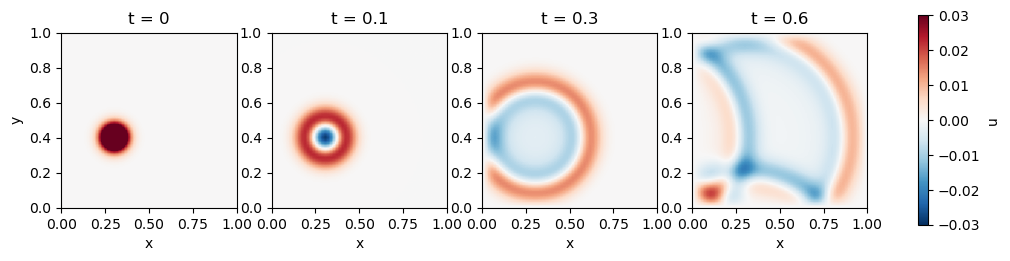

In [8]:
f2 = lambda X, Y: 0.1*np.exp(-((X - 0.3)**2 + (Y - 0.4)**2) / 0.005)
g2 = lambda X, Y: np.zeros_like(X)

n = 60
dt = 0.5 * (1/n) / 1.0          # sigma = c*dt/h = 0,5
T = 0.6
nt = int(round(T / dt))
x, y, t, U = onda_2d(1.0, 1.0, 1.0, T, f2, g2, n, n, nt)
print(f"nt = {nt}, sigma_x^2 + sigma_y^2 = {2*(dt*n)**2:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, tn in zip(axes, [0, 0.1, 0.3, 0.6]):
    k = int(round(tn / dt))
    im = ax.imshow(U[k].T, origin='lower', extent=[0, 1, 0, 1],
                   cmap='RdBu_r', vmin=-0.03, vmax=0.03)
    ax.set_title(f't = {tn}')
    ax.set_xlabel('x')
axes[0].set_ylabel('y')
fig.colorbar(im, ax=axes, shrink=0.8, label='u')
plt.show()

A deformação inicial se espalha como uma onda circular que se afasta do ponto atingido com velocidade $c=1$: em $t=0{,}1$ a frente de onda tem raio próximo de $0{,}1$. Atrás da frente, a membrana passa a oscilar abaixo e acima da posição de equilíbrio, um efeito característico das ondas em duas dimensões. Em $t=0{,}3$ a frente de onda acaba de alcançar a borda $x=0$, que é a mais próxima do ponto atingido. Em $t=0{,}6$ ela já se refletiu nas bordas $x=0$ e $y=0$, com inversão de sinal, como acontece em uma extremidade presa, e as ondas refletidas se superpõem à frente principal, formando o padrão mais complexo do último quadro.

### Exercícios

Utilize a rotina `onda_1d()` (ou, como modelo, a implementação do **Exemplo 8.5.2**) para resolver as equações da onda a seguir e comparar os resultados com a solução exata indicada. Escolha valores adequados de $n_x$, $n_t$ e $T$ que garantam a estabilidade ($\sigma \leq 1$). Os Exercícios 1 a 3 foram adaptados de Burden, Faires e Burden (2016, Seção 12.3).

---

> **1.** Resolva a equação da onda
>
> $$\frac{\partial^2 u}{\partial t^2} - \frac{\partial^2 u}{\partial x^2} = 0, \quad 0 < x < 1, \quad 0 < t,$$
>
> com $u(0,t)=u(1,t)=0$, $u(x,0)=\operatorname{sen}(\pi x)$ e $\dfrac{\partial u}{\partial t}(x,0)=0$.
> Solução exata: $u(x,t)=\cos(\pi t)\operatorname{sen}(\pi x)$.

---

> **2.** Resolva a equação da onda
>
> $$\frac{\partial^2 u}{\partial t^2} - \frac{1}{16\pi^2}\frac{\partial^2 u}{\partial x^2} = 0, \quad 0 < x < 0{,}5, \quad 0 < t,$$
>
> com $u(0,t)=u(0{,}5,t)=0$, $u(x,0)=0$ e $\dfrac{\partial u}{\partial t}(x,0)=\operatorname{sen}(4\pi x)$.
> Solução exata: $u(x,t)=\operatorname{sen}(t)\operatorname{sen}(4\pi x)$.

---

> **3.** Resolva a equação da onda
>
> $$\frac{\partial^2 u}{\partial t^2} - \frac{\partial^2 u}{\partial x^2} = 0, \quad 0 < x < 1, \quad 0 < t,$$
>
> com $u(0,t)=u(1,t)=0$, $u(x,0)=\operatorname{sen}(2\pi x)$ e $\dfrac{\partial u}{\partial t}(x,0)=2\pi\operatorname{sen}(2\pi x)$.
> Solução exata: $u(x,t)=\operatorname{sen}(2\pi x)\,(\cos(2\pi t) + \operatorname{sen}(2\pi t))$.

---

> **4.** Retome a corda triangular do **Exemplo 8.1.6** (Seção 8.1), com $c=1$, $k=1$ e $L=2$, cuja deflexão inicial é
>
> $$f(x)=\begin{cases} x, & 0<x<1 \\ 2-x, & 1<x<2 \end{cases}$$
>
> e velocidade inicial nula. Resolva o problema numericamente com a rotina `onda_1d()` (com $c=1$, deflexão inicial $f$ e velocidade inicial nula) e compare, no mesmo gráfico, a solução numérica com a série de Fourier obtida analiticamente em 8.1 (trunque a série em 20 termos).

---

> **5.** Considere novamente o problema do **Exemplo 8.5.2** ($u_{tt}-4u_{xx}=0$, $u(x,0)=\operatorname{sen}(\pi x)$, $h=0{,}1$). Mantendo $h=0{,}1$, aumente o passo de tempo $k$ até violar a condição de estabilidade $\sigma=\alpha k/h \leq 1$ (por exemplo, $k=0{,}06$). Execute a simulação e plote a solução numérica em função de $x$ para os últimos instantes de tempo. Descreva o que acontece com a amplitude da solução e explique, em termos da Eq. (5), por que isso ocorre.

---

> **6.** Para o modo de vibração $u(x,y,0)=A_0\operatorname{sen}\left(\dfrac{n\pi x}{L_x}\right)\operatorname{sen}\left(\dfrac{m\pi y}{L_y}\right)$ com velocidade inicial nula, mostre (substituindo na EDP $A(u_{xx}+u_{yy})=u_{tt}$) que a solução oscila no tempo com frequência angular
>
> $$\omega_{n,m}=\sqrt{A\left[\left(\frac{n\pi}{L_x}\right)^2+\left(\frac{m\pi}{L_y}\right)^2\right]}.$$
>
> Utilizando a rotina `onda_2d()` (domínio $[0,2]\times[0,2]$, $A=c^2=0{,}25$), simule o modo $n=1$, $m=2$ (isto é, $u(x,y,0)=0{,}1\operatorname{sen}(\pi x/2)\operatorname{sen}(\pi y)$) e meça o período de oscilação observado no centro da membrana. Compare com o período teórico $T_{n,m}=2\pi/\omega_{n,m}$.

---

> **7.** Uma corda de comprimento $1$, presa nas extremidades ($u(0,t)=u(1,t)=0$), é dedilhada fora do centro, no ponto $x=0{,}3$, resultando na deflexão inicial triangular
>
> $$f(x)=\begin{cases} \dfrac{0{,}05}{0{,}3}\,x, & 0\leq x \leq 0{,}3 \\[2mm] \dfrac{0{,}05}{0{,}7}\,(1-x), & 0{,}3 < x \leq 1 \end{cases}$$
>
> com velocidade inicial nula e $c=1$. Resolva com a rotina `onda_1d()` e plote $u(x,t)$ para vários instantes $t$ em um mesmo gráfico. Observe e descreva como o pulso inicial se decompõe em duas ondas viajando em sentidos opostos e como cada uma se reflete ao atingir as extremidades fixas.

---

> **8.** Compare o comportamento qualitativo de uma EDP parabólica e de uma EDP hiperbólica submetidas à mesma condição inicial. Considere, em $0\leq x\leq 1$, com contorno $u(0,t)=u(1,t)=0$ e condição inicial $u(x,0)=\operatorname{sen}(\pi x)$:
>
> (a) a equação do calor $u_t = u_{xx}$, resolvida com a rotina `calor_1d()` da Seção 8.4;
>
> (b) a equação da onda $u_{tt}=u_{xx}$, com velocidade inicial nula, resolvida com a rotina `onda_1d()` desta seção.
>
> Plote, em dois painéis lado a lado, o perfil de $u(x,t)$ para os mesmos instantes de tempo em cada caso. Discuta a diferença qualitativa entre os dois comportamentos (decaimento monótono *versus* oscilação persistente) e relacione isso à ordem da derivada temporal em cada equação.